[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/09_transformer_block.ipynb)

# 09 · Putting It Together: the Transformer Block

*Attention, Explained · Hamza Hentabli, Ph.D. · ~30 min*

Attention is the star, but it never works alone. A **Transformer block** wraps multi-head attention with a **feed-forward network**, **residual connections** and **layer normalisation**. In this notebook we draw the block, build every piece in NumPy and PyTorch, count where the parameters live, and *measure* why residual connections are indispensable.

**Learning objectives.** By the end of this notebook you will be able to:

- draw and explain the **Transformer block** (attention → add & norm → FFN → add & norm)
- implement **LayerNorm**, the **feed-forward** network and a full block in NumPy
- build the block in PyTorch and **count its parameters**
- show with a measurement why **residual connections** matter in deep stacks
- tell **post-norm** from **pre-norm**

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. The block, drawn

A Transformer is a stack of identical **blocks**. Each block has two sub-layers, and each sub-layer is wrapped the same way: **residual connection** (add the input back) and **layer normalisation**.

```
x ─┬─► Multi-Head Self-Attention ─► (+) ─► LayerNorm ─┬─► Feed-Forward ─► (+) ─► LayerNorm ─► out
   └──────────────────────────────────┘                └──────────────────────┘
```

This is the original **post-norm** layout (Vaswani et al., 2017). Most modern models use **pre-norm** (`x + Attn(LN(x))`), which trains more stably when very deep; the ingredients are the same. Below we draw the full picture.

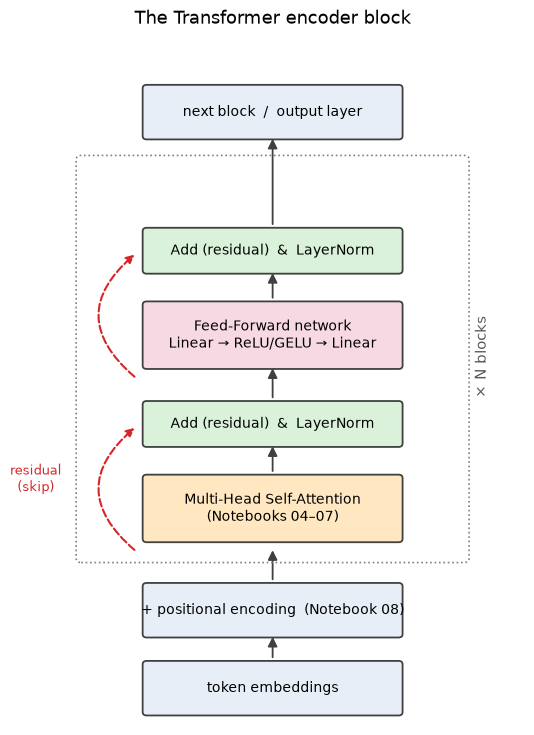

In [2]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(6.5, 9))
ax.set_xlim(0, 10); ax.set_ylim(0, 16); ax.axis("off")
def box(y, text, color, h=1.1, x=2.5, w=5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="0.25", lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10)
def arrow(y0, y1, x=5):
    ax.add_patch(FancyArrowPatch((x, y0), (x, y1), arrowstyle="-|>", mutation_scale=14, color="0.25", lw=1.3))
def skip(y0, y1):
    ax.add_patch(FancyArrowPatch((2.3, y0), (2.3, y1), connectionstyle="arc3,rad=-0.6",
                                 arrowstyle="-|>", mutation_scale=12, color="tab:red", lw=1.5, ls="--"))

box(0.3, "token embeddings", "#e8eef7"); arrow(1.5, 2.1)
box(2.1, "+ positional encoding  (Notebook 08)", "#e8eef7"); arrow(3.3, 4.1)
ax.add_patch(FancyBboxPatch((1.2, 3.85), 7.6, 9.2, boxstyle="round,pad=0.1", fc="none", ec="0.5", lw=1.2, ls=":"))
ax.text(9.0, 8.5, "× N blocks", rotation=90, va="center", fontsize=11, color="0.35")
box(4.3, "Multi-Head Self-Attention\n(Notebooks 04–07)", "#ffe7c2", h=1.4); arrow(5.8, 6.5)
box(6.5, "Add (residual)  &  LayerNorm", "#d9f2d9", h=0.9); skip(4.0, 6.9); arrow(7.5, 8.3)
box(8.3, "Feed-Forward network\nLinear → ReLU/GELU → Linear", "#f7d9e3", h=1.4); arrow(9.8, 10.5)
box(10.5, "Add (residual)  &  LayerNorm", "#d9f2d9", h=0.9); skip(8.0, 10.9); arrow(11.5, 13.6)
box(13.6, "next block  /  output layer", "#e8eef7")
ax.text(0.3, 5.4, "residual\n(skip)", color="tab:red", fontsize=9, ha="center")
ax.set_title("The Transformer encoder block", fontsize=13)
au.save_fig(fig, "09_transformer_block.png")
plt.show()

## 2. The pieces in NumPy

### Layer normalisation

For **each token separately**, subtract the mean and divide by the standard deviation across its features, then apply a learned scale $\gamma$ and shift $\beta$:

$$\text{LN}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta$$

In [3]:
import torch
import torch.nn as nn

def layer_norm(x, gamma, beta, eps=1e-5):
    mu = x.mean(-1, keepdims=True)
    var = x.var(-1, keepdims=True)
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

rng = np.random.default_rng(0)
x = rng.normal(loc=3, scale=5, size=(4, 8))      # 4 tokens, 8 features, deliberately off-centre
y = layer_norm(x, np.ones(8), np.zeros(8))
print("before: per-token mean", x.mean(1).round(2), " std", x.std(1).round(2))
print("after : per-token mean", y.mean(1).round(2), " std", y.std(1).round(2))
print("matches torch.nn.LayerNorm:", np.allclose(y, nn.LayerNorm(8)(torch.tensor(x, dtype=torch.float32)).detach().numpy(), atol=1e-5))

before: per-token mean [ 4.76 -1.42  3.95  1.67]  std [2.78 3.43 3.45 3.05]
after : per-token mean [-0.  0. -0. -0.]  std [1. 1. 1. 1.]
matches torch.nn.LayerNorm: True


### Feed-forward network

A two-layer MLP applied to **each position independently** (same weights for every token), usually 4× wider in the middle. Attention *mixes information between tokens*; the feed-forward network *processes each token's mixed information*.

In [4]:
def feed_forward(x, W1, b1, W2, b2):
    return np.maximum(0, x @ W1 + b1) @ W2 + b2      # ReLU in the middle

def mha(X, WQ, WK, WV, WO, n_heads):
    T, dm = X.shape; dh = dm // n_heads
    split = lambda M: M.reshape(T, n_heads, dh).transpose(1, 0, 2)
    Z, A = au.scaled_dot_product_attention(split(X @ WQ), split(X @ WK), split(X @ WV))
    return Z.transpose(1, 0, 2).reshape(T, dm) @ WO, A

def transformer_block(X, p, n_heads=2):
    attn_out, A = mha(X, p["WQ"], p["WK"], p["WV"], p["WO"], n_heads)
    X = layer_norm(X + attn_out, p["g1"], p["b1n"])                         # Add & Norm
    X = layer_norm(X + feed_forward(X, p["W1"], p["b1"], p["W2"], p["b2"]), p["g2"], p["b2n"])   # Add & Norm
    return X, A

d_model, d_ff, T = 8, 32, 5
s = d_model ** -0.5
p = {k: rng.normal(scale=s, size=(d_model, d_model)) for k in ("WQ", "WK", "WV", "WO")}
p.update(W1=rng.normal(scale=s, size=(d_model, d_ff)), b1=np.zeros(d_ff),
         W2=rng.normal(scale=d_ff ** -0.5, size=(d_ff, d_model)), b2=np.zeros(d_model),
         g1=np.ones(d_model), b1n=np.zeros(d_model), g2=np.ones(d_model), b2n=np.zeros(d_model))
X = rng.normal(size=(T, d_model))
out, A = transformer_block(X, p)
print("input", X.shape, "-> block output", out.shape, "(same shape: blocks can be stacked)")

input (5, 8) -> block output (5, 8) (same shape: blocks can be stacked)


### The same block in PyTorch, and where the parameters live

In [5]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, pre_norm=False):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.pre_norm = pre_norm
    def forward(self, x):
        if self.pre_norm:                                   # modern layout
            h = self.ln1(x); x = x + self.attn(h, h, h, need_weights=False)[0]
            return x + self.ff(self.ln2(x))
        x = self.ln1(x + self.attn(x, x, x, need_weights=False)[0])   # original layout
        return self.ln2(x + self.ff(x))

blk = TransformerBlock(d_model=512, n_heads=8, d_ff=2048)
groups = {"attention (W_Q, W_K, W_V, W_O)": blk.attn, "feed-forward": blk.ff, "layer norms": nn.ModuleList([blk.ln1, blk.ln2])}
total = sum(q.numel() for q in blk.parameters())
for name, mod in groups.items():
    n = sum(q.numel() for q in mod.parameters())
    print(f"{name:32s} {n:>10,d}  ({100 * n / total:4.1f}%)")
print(f"{'total per block (d=512, as in the 2017 paper)':32s} {total:>10,d}")

attention (W_Q, W_K, W_V, W_O)    1,050,624  (33.3%)
feed-forward                      2,099,712  (66.6%)
layer norms                           2,048  ( 0.1%)
total per block (d=512, as in the 2017 paper)  3,152,384


About **two thirds of a block's parameters are in the feed-forward network**, not in attention — a fact that surprises many people.

## 3. Why residual connections? Two measurements

A residual connection computes $x + f(x)$ instead of $f(x)$. Two things go wrong without it in a deep stack of attention layers:

1. **Tokens blur together.** Each attention layer replaces every token by a weighted *average* of tokens. Average enough times and every position ends up with the same vector (*rank collapse*, Dong et al., 2021). The residual keeps each token's own information flowing.
2. **Training stalls**, because the signal and the gradient have to squeeze through every layer instead of taking the direct path $\partial(x + f(x))/\partial x = I + \partial f/\partial x$.

Both are easy to measure. We use the same sub-layers (LayerNorm → attention, LayerNorm → FFN), once with and once without the residual additions.

In [6]:
import torch.nn.functional as F
torch.set_num_threads(4)

class Sublayers(nn.Module):
    """Attention + FFN (pre-norm), with or without the residual additions."""
    def __init__(self, d, residual):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, 4, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.ln1, self.ln2, self.residual = nn.LayerNorm(d), nn.LayerNorm(d), residual
    def forward(self, x):
        h = self.ln1(x)
        a = self.attn(h, h, h, need_weights=False)[0]
        x = x + a if self.residual else a
        f = self.ff(self.ln2(x))
        return x + f if self.residual else f

def token_similarity(depth, residual, seed=0):
    """Mean cosine similarity between DIFFERENT token vectors after `depth` random blocks."""
    torch.manual_seed(seed)
    net = nn.Sequential(*[Sublayers(32, residual) for _ in range(depth)])
    with torch.no_grad():
        y = F.normalize(net(torch.randn(8, 10, 32)), dim=-1)
    c = y @ y.transpose(1, 2)
    return ((c.sum((1, 2)) - 10) / 90).mean().item()

depths = [1, 2, 4, 8, 16, 24]
sim_res = [token_similarity(d_, True) for d_ in depths]
sim_nores = [token_similarity(d_, False) for d_ in depths]
for d_, a_, b_ in zip(depths, sim_res, sim_nores):
    print(f"{d_:2d} blocks: mean cosine between different tokens  with residuals {a_:.3f}   without {b_:.3f}")

 1 blocks: mean cosine between different tokens  with residuals 0.026   without 0.769
 2 blocks: mean cosine between different tokens  with residuals 0.048   without 0.995
 4 blocks: mean cosine between different tokens  with residuals 0.050   without 1.000
 8 blocks: mean cosine between different tokens  with residuals 0.118   without 1.000
16 blocks: mean cosine between different tokens  with residuals 0.283   without 1.000
24 blocks: mean cosine between different tokens  with residuals 0.373   without 1.000


Without residuals, after only a couple of blocks every token points in (almost) the same direction — cosine ≈ 1 — so the sentence has collapsed into one repeated vector. With residuals the tokens stay distinct.

Now the training consequence: a 12-block model learning to **reverse** a sequence of 10 tokens (the task from Notebook 01), 300 steps, identical except for the residuals.

with residual connections      loss at start 3.137, mean of last 20 steps 0.0010
without residual connections   loss at start 2.784, mean of last 20 steps 2.7666


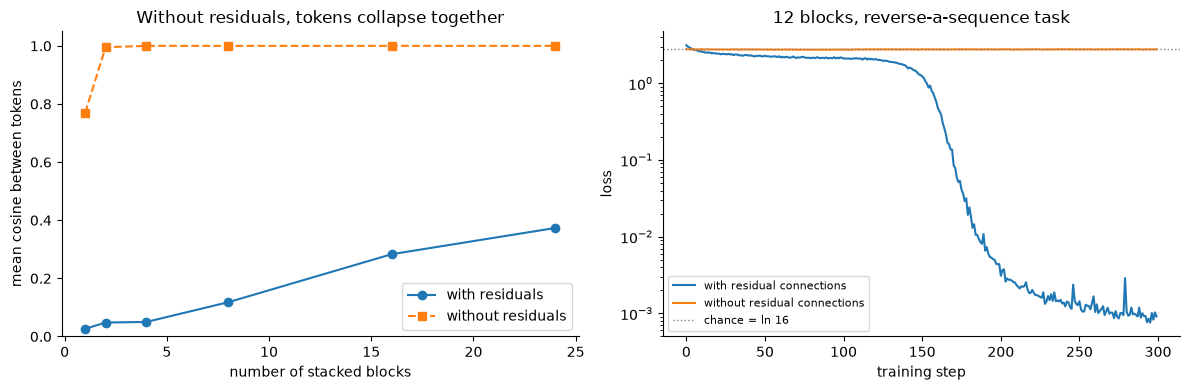

In [7]:
VOCAB, L, D = 16, 10, 32
def train_deep(residual, depth=12, steps=300):
    torch.manual_seed(0)
    emb, out = nn.Embedding(VOCAB, D), nn.Linear(D, VOCAB)
    pos = nn.Parameter(torch.randn(L, D) * 0.5)
    net = nn.Sequential(*[Sublayers(D, residual) for _ in range(depth)])
    opt = torch.optim.Adam([*emb.parameters(), pos, *net.parameters(), *out.parameters()], lr=1e-3)
    losses = []
    for _ in range(steps):
        x = torch.randint(0, VOCAB, (64, L))
        logits = out(net(emb(x) + pos))
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), x.flip(1).reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return losses

curves = {"with residual connections": train_deep(True), "without residual connections": train_deep(False)}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(depths, sim_res, "o-", label="with residuals"); axes[0].plot(depths, sim_nores, "s--", label="without residuals")
axes[0].set_xlabel("number of stacked blocks"); axes[0].set_ylabel("mean cosine between tokens"); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Without residuals, tokens collapse together"); axes[0].legend()
for name, c in curves.items():
    axes[1].plot(c, label=name)
    print(f"{name:30s} loss at start {c[0]:.3f}, mean of last 20 steps {np.mean(c[-20:]):.4f}")
axes[1].axhline(np.log(VOCAB), color="grey", ls=":", lw=1, label=f"chance = ln {VOCAB}")
axes[1].set_yscale("log"); axes[1].set_xlabel("training step"); axes[1].set_ylabel("loss")
axes[1].set_title("12 blocks, reverse-a-sequence task"); axes[1].legend(fontsize=8)
plt.tight_layout()
au.save_fig(fig, "09_residual_ablation.png")
plt.show()

With residuals the 12-block model learns the task; without them the loss stays at the chance level of $\ln 16 \approx 2.77$, because the collapsed representations no longer say which token was where. That is why every Transformer, whether it has 6 blocks or 100, wraps every sub-layer in a skip connection.

## Key takeaways

- A **Transformer block** = multi-head self-attention + feed-forward network, each wrapped in **residual + LayerNorm**.
- **LayerNorm** normalises each token's features; the **FFN** processes each token independently and holds most of the parameters.
- **Residual connections** keep tokens distinct and deep stacks trainable — measured above.
- Input and output shapes match, so blocks **stack**.

### ✏️ Exercise 1

Stack the NumPy `transformer_block` 3 times (reuse `p`) and check the output shape and per-token mean/std.

<details>
<summary><b>Show solution</b></summary>

```python
H = X
for _ in range(3):
    H, _ = transformer_block(H, p)
print(H.shape, H.mean(1).round(3), H.std(1).round(3))
```

After a final LayerNorm each token has mean ≈ 0 and std ≈ 1.

</details>

### ✏️ Exercise 2

Count the parameters of a **pre-norm** block with `d_model=768, n_heads=12, d_ff=3072` (the BERT-base / GPT-2 small size). Multiply by 12 blocks.

<details>
<summary><b>Show solution</b></summary>

```python
b = TransformerBlock(768, 12, 3072, pre_norm=True)
n = sum(q.numel() for q in b.parameters())
print(f"{n:,} per block, {12 * n:,} for 12 blocks")
```

≈ 7.1 M per block, ≈ 85 M for 12 blocks — most of BERT-base's 110 M (the rest is the embedding table).

</details>

### ✏️ Exercise 3

Check that the PyTorch block works on a batch: `blk(torch.randn(2, 7, 512)).shape`.

<details>
<summary><b>Show solution</b></summary>

```python
print(blk(torch.randn(2, 7, 512)).shape)
```



</details>